In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [16]:
from pathlib import Path
import os

if Path.cwd().name == "notebooks":
    os.chdir("..")

In [17]:
import pandas as pd

ba_cityflyer = pd.read_csv(
    "data/processed/ba_cityflyer_2019_2026.csv",
    parse_dates=["date"]
)

print("Dataset shape:", ba_cityflyer.shape)

Dataset shape: (91, 19)


In [18]:
ba_cityflyer = pd.read_csv(
    "data/processed/ba_cityflyer_2019_2026.csv",
    parse_dates=["date"]
)

print("Dataset shape:", ba_cityflyer.shape)

ba_cityflyer.head()

Dataset shape: (91, 19)


,rundate,reporting_period,type_of_operations,airline_name,aircraft_km_x1000,no_flights,aircraft_hours,total_passengers_uplifted,seat_km_available_x1000,seat_km_used_x1000,cargo_tonnes_uplifted,total_tonne_km_available_x1000,tot_mail_tonne_km_used_x1000,total_freight_tonne_km_used_x1000,total_passenger_tonne_km_used_x1000,load_factor_pct,date,passengers_per_flight,avg_flight_distance_km
0,07/03/2019 11:11,201901,Passenger,BA CITYFLYER LTD,2027,3059,4376,174199,189033,118930,0,18903,0,0,10381,62.914941,2019-01-01,56.946388,662.634848
1,7/12/2019 4:50:06 AM,201902,Passenger,BA CITYFLYER LTD,2168,3334,4792,204657,199610,138504,0,19969,0,0,12038,69.387305,2019-02-01,61.384823,650.269946
2,6/14/2019 4:06:46 PM,201903,Passenger,BA CITYFLYER LTD,2447,3683,5407,235098,225254,161667,0,22547,0,0,14026,71.770979,2019-03-01,63.833288,664.404018
3,7/12/2019 5:04:07 AM,201904,Passenger,BA CITYFLYER LTD,2363,3551,5143,226066,218022,154725,0,21824,0,0,13478,70.967609,2019-04-01,63.662630,665.446353
4,8/20/2019 9:45:48 AM,201905,Passenger,BA CITYFLYER LTD,2795,3922,5929,256239,258281,187885,0,25855,0,0,16404,72.744414,2019-05-01,65.333758,712.646609


In [19]:
ba_cityflyer = pd.read_csv(
    "data/processed/ba_cityflyer_2019_2026.csv",
    parse_dates=["date"]
)

print("Dataset shape:", ba_cityflyer.shape)

ba_cityflyer.head()

Dataset shape: (91, 19)


,rundate,reporting_period,type_of_operations,airline_name,aircraft_km_x1000,no_flights,aircraft_hours,total_passengers_uplifted,seat_km_available_x1000,seat_km_used_x1000,cargo_tonnes_uplifted,total_tonne_km_available_x1000,tot_mail_tonne_km_used_x1000,total_freight_tonne_km_used_x1000,total_passenger_tonne_km_used_x1000,load_factor_pct,date,passengers_per_flight,avg_flight_distance_km
0,07/03/2019 11:11,201901,Passenger,BA CITYFLYER LTD,2027,3059,4376,174199,189033,118930,0,18903,0,0,10381,62.914941,2019-01-01,56.946388,662.634848
1,7/12/2019 4:50:06 AM,201902,Passenger,BA CITYFLYER LTD,2168,3334,4792,204657,199610,138504,0,19969,0,0,12038,69.387305,2019-02-01,61.384823,650.269946
2,6/14/2019 4:06:46 PM,201903,Passenger,BA CITYFLYER LTD,2447,3683,5407,235098,225254,161667,0,22547,0,0,14026,71.770979,2019-03-01,63.833288,664.404018
3,7/12/2019 5:04:07 AM,201904,Passenger,BA CITYFLYER LTD,2363,3551,5143,226066,218022,154725,0,21824,0,0,13478,70.967609,2019-04-01,63.662630,665.446353
4,8/20/2019 9:45:48 AM,201905,Passenger,BA CITYFLYER LTD,2795,3922,5929,256239,258281,187885,0,25855,0,0,16404,72.744414,2019-05-01,65.333758,712.646609


In [20]:
ba_cityflyer["year"] = ba_cityflyer["date"].dt.year

annual_passengers = (
    ba_cityflyer.groupby("year")["total_passengers_uplifted"]
    .sum()
)

annual_passengers

year
2019    2827616
2020     514363
2021     635340
2022    2254214
2023    2431759
2024    2384607
2025    2522572
2026    1418527
Name: total_passengers_uplifted, dtype: int64

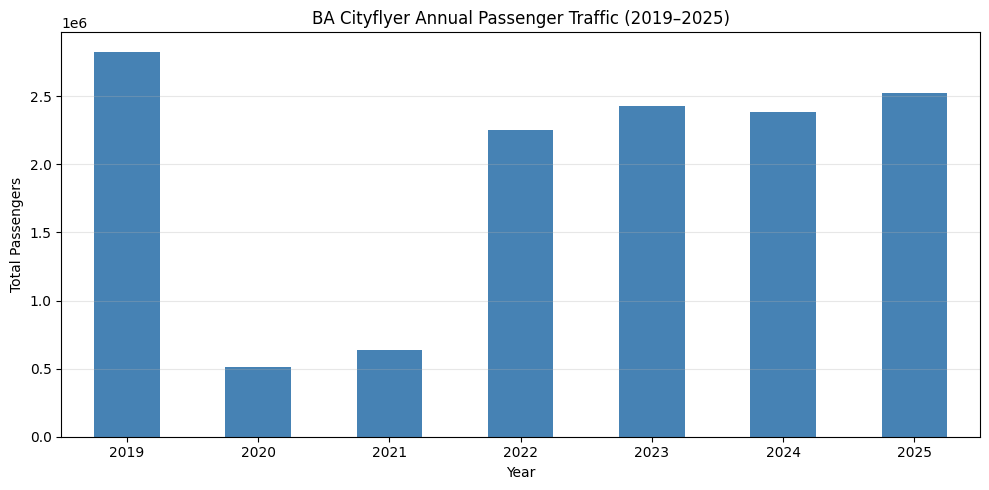

In [21]:
annual_passengers.loc[2019:2025].plot(
    kind="bar",
    figsize=(10, 5),
    color="steelblue"
)

plt.title("BA Cityflyer Annual Passenger Traffic (2019–2025)")
plt.xlabel("Year")
plt.ylabel("Total Passengers")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
passengers_2019 = annual_passengers.loc[2019]
passengers_2025 = annual_passengers.loc[2025]

percentage_change = (
    (passengers_2025 - passengers_2019)
    / passengers_2019
) * 100

print(f"Passenger change (2019–2025): {percentage_change:.2f}%")

Passenger change (2019–2025): -10.79%


In [23]:
annual_flights = (
    ba_cityflyer.groupby("year")["no_flights"]
    .sum()
)

annual_flights

year
2019    42406
2020     9558
2021    10489
2022    31017
2023    33236
2024    30369
2025    30870
2026    17626
Name: no_flights, dtype: int64

In [24]:
flights_2019 = annual_flights.loc[2019]
flights_2025 = annual_flights.loc[2025]

flight_change_pct = (
    (flights_2025 - flights_2019)
    / flights_2019
) * 100

print(f"Flight change (2019–2025): {flight_change_pct:.2f}%")

Flight change (2019–2025): -27.20%


In [25]:
annual_passengers_per_flight = (
    annual_passengers / annual_flights
)

print("2019:", round(annual_passengers_per_flight.loc[2019], 2))
print("2025:", round(annual_passengers_per_flight.loc[2025], 2))

2019: 66.68
2025: 81.72


In [26]:
passengers_per_flight_change = (
    (annual_passengers_per_flight.loc[2025]
     - annual_passengers_per_flight.loc[2019])
    / annual_passengers_per_flight.loc[2019]
) * 100

print(
    f"Change in passengers per flight: "
    f"{passengers_per_flight_change:.2f}%"
)

Change in passengers per flight: 22.55%


In [27]:
annual_load_factor = (
    ba_cityflyer.groupby("year")["seat_km_used_x1000"].sum()
    / ba_cityflyer.groupby("year")["seat_km_available_x1000"].sum()
) * 100

annual_load_factor.round(2)

year
2019    74.70
2020    61.85
2021    64.26
2022    76.83
2023    77.40
2024    80.30
2025    78.92
2026    77.86
dtype: float64

In [28]:
annual_capacity = (
    ba_cityflyer.groupby("year")["seat_km_available_x1000"]
    .sum()
)

annual_capacity.loc[[2019, 2024, 2025]]

year
2019    2919965
2024    2305741
2025    2462567
Name: seat_km_available_x1000, dtype: int64

In [29]:
annual_used_capacity = (
    ba_cityflyer.groupby("year")["seat_km_used_x1000"]
    .sum()
)

capacity_growth = (
    annual_capacity.loc[2025] / annual_capacity.loc[2024] - 1
) * 100

used_capacity_growth = (
    annual_used_capacity.loc[2025] / annual_used_capacity.loc[2024] - 1
) * 100

print(f"Available seat-km growth: {capacity_growth:.2f}%")
print(f"Used seat-km growth: {used_capacity_growth:.2f}%")

Available seat-km growth: 6.80%
Used seat-km growth: 4.97%


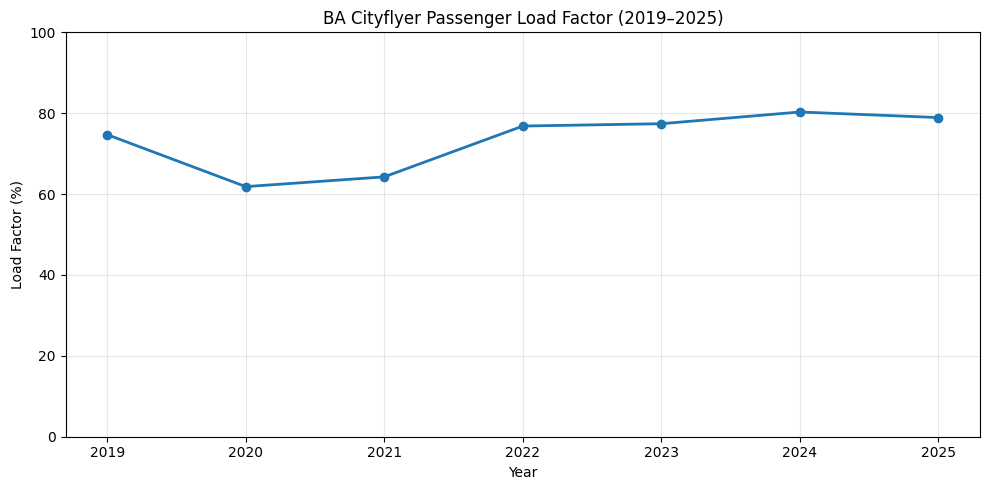

In [30]:
plt.figure(figsize=(10, 5))

plt.plot(
    annual_load_factor.loc[2019:2025].index,
    annual_load_factor.loc[2019:2025].values,
    marker="o",
    linewidth=2
)

plt.title("BA Cityflyer Passenger Load Factor (2019–2025)")
plt.xlabel("Year")
plt.ylabel("Load Factor (%)")
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [31]:
ba_cityflyer["month"] = ba_cityflyer["date"].dt.month

monthly_average_passengers = (
    ba_cityflyer[ba_cityflyer["year"].between(2022, 2025)]
    .groupby("month")["total_passengers_uplifted"]
    .mean()
)

monthly_average_passengers.round(0)

month
1     120079.0
2     147435.0
3     186406.0
4     183289.0
5     214214.0
6     238721.0
7     247487.0
8     235573.0
9     229453.0
10    219475.0
11    195666.0
12    180490.0
Name: total_passengers_uplifted, dtype: float64

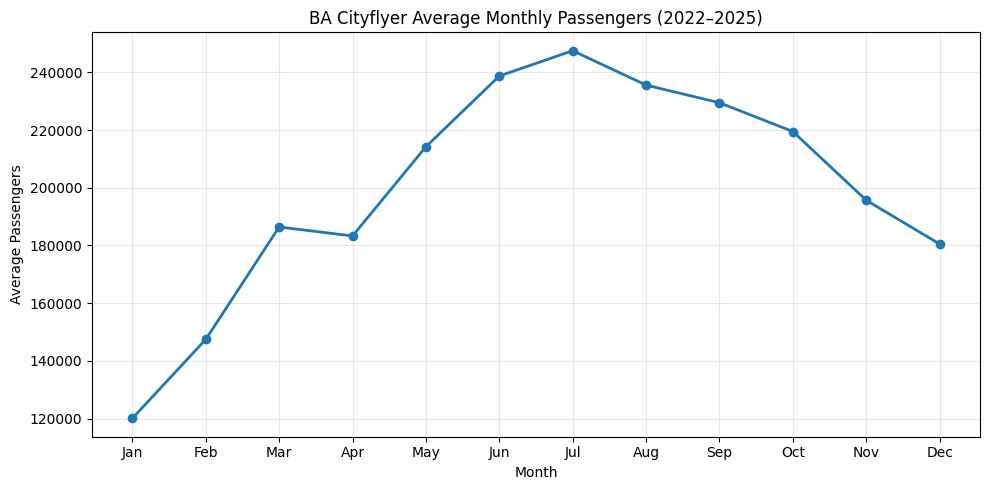

In [32]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_average_passengers.index,
    monthly_average_passengers.values,
    marker="o",
    linewidth=2
)

plt.title("BA Cityflyer Average Monthly Passengers (2022–2025)")
plt.xlabel("Month")
plt.ylabel("Average Passengers")

plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
seasonal_data = ba_cityflyer[
    ba_cityflyer["year"].between(2022, 2025)
]

monthly_load_factor = (
    seasonal_data.groupby("month")["seat_km_used_x1000"].sum()
    / seasonal_data.groupby("month")["seat_km_available_x1000"].sum()
) * 100

monthly_load_factor.round(2)

month
1     64.55
2     70.76
3     74.55
4     74.01
5     76.10
6     83.69
7     84.94
8     82.35
9     83.61
10    77.70
11    75.86
12    77.67
dtype: float64

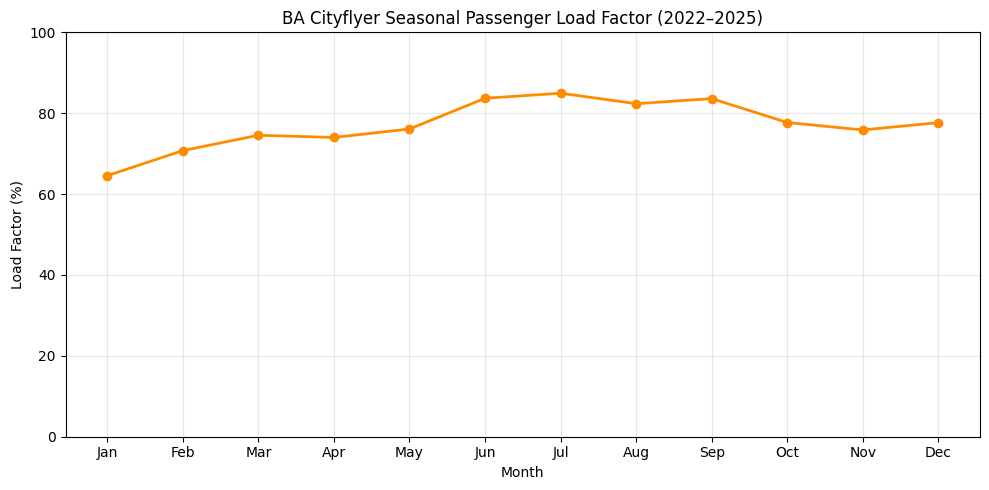

In [34]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_load_factor.index,
    monthly_load_factor.values,
    marker="o",
    linewidth=2,
    color="darkorange"
)

plt.title("BA Cityflyer Seasonal Passenger Load Factor (2022–2025)")
plt.xlabel("Month")
plt.ylabel("Load Factor (%)")

plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [35]:
ba_cityflyer["passenger_yoy_pct"] = (
    ba_cityflyer["total_passengers_uplifted"]
    .pct_change(periods=12) * 100
)

ba_cityflyer[[
    "date",
    "total_passengers_uplifted",
    "passenger_yoy_pct"
]].tail(12).round({"passenger_yoy_pct": 2})

,date,total_passengers_uplifted,passenger_yoy_pct
79,2025-08-01,236161,4.99
80,2025-09-01,242246,8.68
81,2025-10-01,226961,3.44
82,2025-11-01,199217,0.95
83,2025-12-01,183013,1.11
84,2026-01-01,148245,3.24
85,2026-02-01,168210,1.36
86,2026-03-01,201824,-1.37
87,2026-04-01,194242,-1.91
88,2026-05-01,213389,-2.45


In [36]:
ytd_passengers = (
    ba_cityflyer[
        (ba_cityflyer["year"].isin([2025, 2026]))
        & (ba_cityflyer["month"] <= 7)
    ]
    .groupby("year")["total_passengers_uplifted"]
    .sum()
)

ytd_growth = (
    ytd_passengers.loc[2026] / ytd_passengers.loc[2025] - 1
) * 100

print(ytd_passengers)
print(f"\n2026 YTD passenger growth: {ytd_growth:.2f}%")

year
2025    1434974
2026    1418527
Name: total_passengers_uplifted, dtype: int64

2026 YTD passenger growth: -1.15%


In [37]:
ytd_flights = (
    ba_cityflyer[
        (ba_cityflyer["year"].isin([2025, 2026]))
        & (ba_cityflyer["month"] <= 7)
    ]
    .groupby("year")["no_flights"]
    .sum()
)

flight_ytd_growth = (
    ytd_flights.loc[2026] / ytd_flights.loc[2025] - 1
) * 100

print(ytd_flights)
print(f"\n2026 YTD flight growth: {flight_ytd_growth:.2f}%")

year
2025    17669
2026    17626
Name: no_flights, dtype: int64

2026 YTD flight growth: -0.24%


In [38]:
ytd_data = ba_cityflyer[
    (ba_cityflyer["year"].isin([2025, 2026]))
    & (ba_cityflyer["month"] <= 7)
]

ytd_load_factor = (
    ytd_data.groupby("year")["seat_km_used_x1000"].sum()
    / ytd_data.groupby("year")["seat_km_available_x1000"].sum()
) * 100

print(ytd_load_factor.round(2))

print(
    "Load factor change:",
    round(ytd_load_factor.loc[2026] - ytd_load_factor.loc[2025], 2),
    "percentage points"
)

year
2025    78.35
2026    77.86
dtype: float64
Load factor change: -0.49 percentage points


In [39]:
correlation = ba_cityflyer[
    ["no_flights", "total_passengers_uplifted"]
].corr()

correlation

,no_flights,total_passengers_uplifted
no_flights,1.000000,0.965164
total_passengers_uplifted,0.965164,1.000000


In [40]:
post_pandemic = ba_cityflyer[
    ba_cityflyer["year"].between(2022, 2025)
]

post_pandemic_correlation = post_pandemic[
    ["no_flights", "total_passengers_uplifted"]
].corr()

post_pandemic_correlation

,no_flights,total_passengers_uplifted
no_flights,1.000000,0.895755
total_passengers_uplifted,0.895755,1.000000


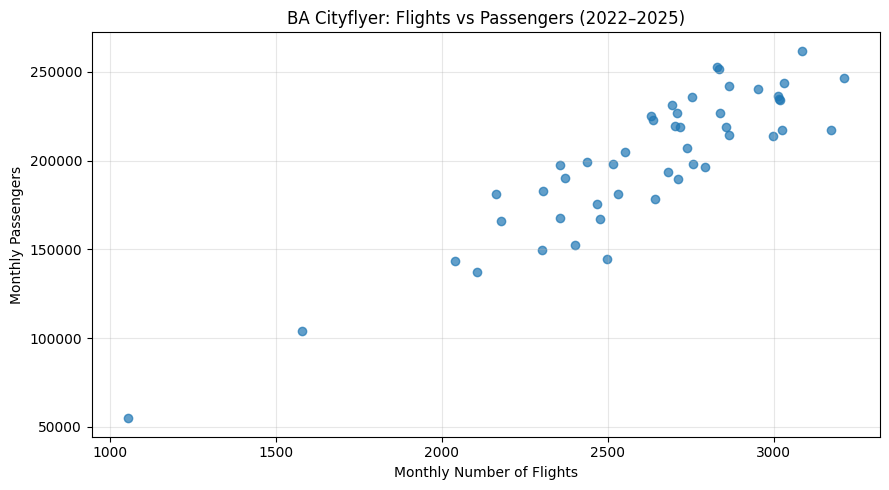

In [41]:
plt.figure(figsize=(9, 5))

plt.scatter(
    post_pandemic["no_flights"],
    post_pandemic["total_passengers_uplifted"],
    alpha=0.7
)

plt.title("BA Cityflyer: Flights vs Passengers (2022–2025)")
plt.xlabel("Monthly Number of Flights")
plt.ylabel("Monthly Passengers")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [42]:
post_pandemic.nsmallest(
    5, "no_flights"
)[[
    "date",
    "no_flights",
    "total_passengers_uplifted",
    "load_factor_pct"
]]

,date,no_flights,total_passengers_uplifted,load_factor_pct
36,2022-01-01,1053,54736,57.219766
37,2022-02-01,1577,104205,69.983478
72,2025-01-01,2041,143586,68.171523
60,2024-01-01,2107,137319,69.154909
71,2024-12-01,2163,181000,79.369833


In [43]:
correlation_2023_2025 = (
    ba_cityflyer[
        ba_cityflyer["year"].between(2023, 2025)
    ][["no_flights", "total_passengers_uplifted"]]
    .corr()
    .loc["no_flights", "total_passengers_uplifted"]
)

print(f"Correlation (2022–2025): {0.895755:.4f}")
print(f"Correlation (2023–2025): {correlation_2023_2025:.4f}")

Correlation (2022–2025): 0.8958
Correlation (2023–2025): 0.8077


In [44]:
load_factor_correlation = (
    ba_cityflyer[
        ba_cityflyer["year"].between(2023, 2025)
    ][["total_passengers_uplifted", "load_factor_pct"]]
    .corr()
)

load_factor_correlation

,total_passengers_uplifted,load_factor_pct
total_passengers_uplifted,1.00000,0.85771
load_factor_pct,0.85771,1.00000


In [45]:
passengers_load_correlation = (
    ba_cityflyer[
        ba_cityflyer["year"].between(2023, 2025)
    ][["passengers_per_flight", "load_factor_pct"]]
    .corr()
)

passengers_load_correlation

,passengers_per_flight,load_factor_pct
passengers_per_flight,1.000000,0.878176
load_factor_pct,0.878176,1.000000


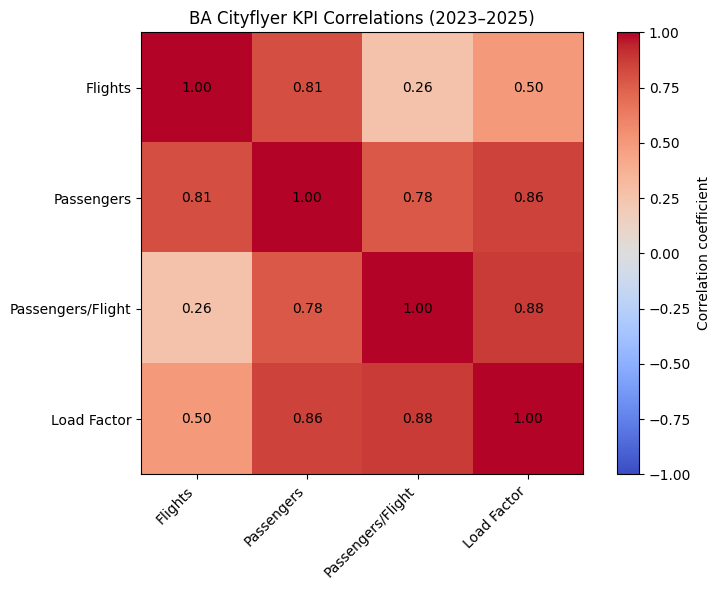

In [46]:
kpi_columns = [
    "no_flights",
    "total_passengers_uplifted",
    "passengers_per_flight",
    "load_factor_pct"
]

correlation_matrix = (
    ba_cityflyer[
        ba_cityflyer["year"].between(2023, 2025)
    ][kpi_columns]
    .corr()
)

fig, ax = plt.subplots(figsize=(8, 6))

image = ax.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(kpi_columns)))
ax.set_yticks(range(len(kpi_columns)))

labels = [
    "Flights",
    "Passengers",
    "Passengers/Flight",
    "Load Factor"
]

ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_yticklabels(labels)

for i in range(len(kpi_columns)):
    for j in range(len(kpi_columns)):
        ax.text(
            j, i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.colorbar(image, label="Correlation coefficient")
plt.title("BA Cityflyer KPI Correlations (2023–2025)")
plt.tight_layout()
plt.show()

In [47]:
growth_stats = (
    ba_cityflyer[
        ba_cityflyer["year"].between(2023, 2025)
    ]["passenger_yoy_pct"]
    .agg(["mean", "median", "std", "min", "max"])
)

growth_stats.round(2)

mean        8.11
median      1.43
std        28.77
min        -6.84
max       164.32
Name: passenger_yoy_pct, dtype: float64

In [48]:
growth_period = ba_cityflyer[
    ba_cityflyer["year"].between(2023, 2025)
]

growth_period.loc[
    growth_period["passenger_yoy_pct"].idxmax(),
    ["date", "total_passengers_uplifted", "passenger_yoy_pct"]
]

date                         2023-01-01 00:00:00
total_passengers_uplifted                 144676
passenger_yoy_pct                     164.315989
Name: 48, dtype: object

In [49]:
jan_2022 = 54736
jan_2023 = 144676

growth = ((jan_2023 - jan_2022) / jan_2022) * 100

print(f"January 2023 YoY growth: {growth:.2f}%")

January 2023 YoY growth: 164.32%


In [50]:
growth_without_jan2023 = growth_period[
    growth_period["date"] != "2023-01-01"
]

print(
    "Original mean:",
    round(growth_period["passenger_yoy_pct"].mean(), 2)
)

print(
    "Mean excluding January 2023:",
    round(growth_without_jan2023["passenger_yoy_pct"].mean(), 2)
)

Original mean: 8.11
Mean excluding January 2023: 3.65


In [51]:
print(
    "Original median:",
    round(growth_period["passenger_yoy_pct"].median(), 2)
)

print(
    "Median excluding January 2023:",
    round(growth_without_jan2023["passenger_yoy_pct"].median(), 2)
)

Original median: 1.43
Median excluding January 2023: 1.27


In [52]:
annual_summary = pd.DataFrame({
    "Passengers": annual_passengers,
    "Flights": annual_flights,
    "Passengers_per_flight": annual_passengers_per_flight,
    "Load_factor_pct": annual_load_factor
})

annual_summary.round(2)

,Passengers,Flights,Passengers_per_flight,Load_factor_pct
year,,,,
2019,2827616,42406,66.68,74.70
2020,514363,9558,53.81,61.85
2021,635340,10489,60.57,64.26
2022,2254214,31017,72.68,76.83
2023,2431759,33236,73.17,77.40
2024,2384607,30369,78.52,80.30
2025,2522572,30870,81.72,78.92
2026,1418527,17626,80.48,77.86


In [53]:
annual_summary.to_csv(
    "data/processed/ba_cityflyer_annual_summary.csv",
    index=True
)

print("Annual summary exported successfully.")

Annual summary exported successfully.


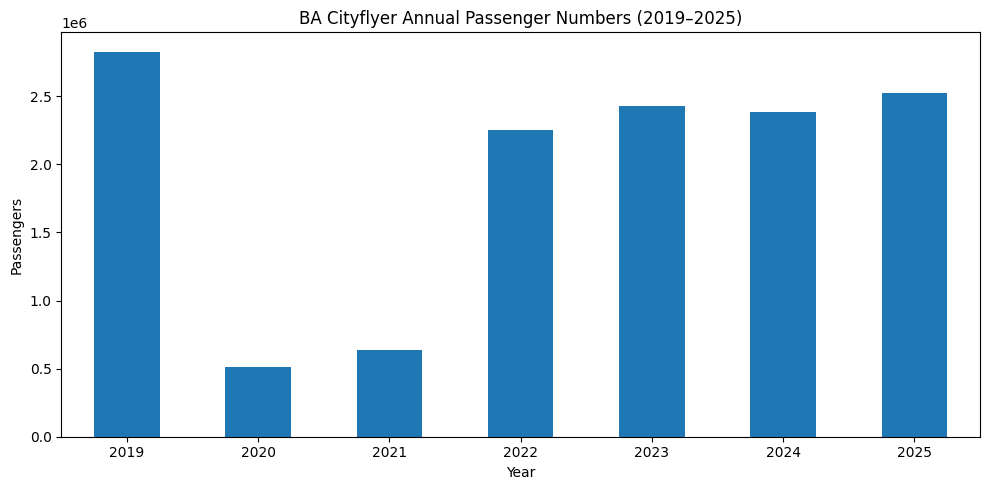

In [54]:
import os

os.makedirs("reports/figures", exist_ok=True)

fig, ax = plt.subplots(figsize=(10, 5))

annual_passengers.loc[2019:2025].plot(
    kind="bar",
    ax=ax
)

ax.set_title("BA Cityflyer Annual Passenger Numbers (2019–2025)")
ax.set_xlabel("Year")
ax.set_ylabel("Passengers")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()

fig.savefig(
    "reports/figures/ba_cityflyer_annual_passengers.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Conclusions and Commercial Insights

The analysis of BA Cityflyer's operational performance between January 2019 and July 2026 identifies several important findings.

### Key Findings

1. **Passenger recovery:** Passenger numbers recovered significantly following the COVID-19 pandemic. However, 2025 passenger volumes remained 10.79% below 2019 levels.

2. **Flight utilisation:** BA Cityflyer operated 27.20% fewer flights in 2025 than in 2019, while average passengers per flight increased by 22.55%.

3. **Load factor improvement:** Annual load factor increased from 74.70% in 2019 to 78.92% in 2025, suggesting improved utilisation of available seat-kilometre capacity.

4. **Seasonality:** Passenger demand and load factors are generally strongest during the summer months, particularly July, while January experiences weaker demand.

5. **Recent performance:** Passenger numbers for January–July 2026 were 1.15% lower than the corresponding period in 2025.

6. **Growth volatility:** Exceptionally high year-on-year growth in January 2023 demonstrates how recovery from a low base can distort average growth rates. Median growth provides a useful alternative measure.

### Commercial Implications

- Investigate opportunities to align flight capacity with seasonal passenger demand.
- Monitor load factors alongside passenger volumes and flight frequency.
- Evaluate whether capacity adjustments could improve utilisation during weaker months.
- Use historical demand patterns to support forecasting and operational planning.

### Limitations

- The analysis uses airline-level CAA statistics rather than individual route-level data.
- Passenger volumes and load factors do not directly measure profitability.
- Aircraft types, ticket prices, operating costs and revenue are not included.
- Correlation does not establish causation.
- The 2026 dataset covers January–July only and is not directly comparable with complete calendar years.

### Overall Conclusion

BA Cityflyer's passenger traffic has recovered substantially since the pandemic, although annual passenger volumes remain below 2019 levels. Higher passengers per flight and improved load factors suggest stronger capacity utilisation, while seasonal fluctuations highlight opportunities for further operational analysis.